[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IMForg-Public/imf_big_data_workshop_sti26/blob/main/notebooks/BDC_Builtup_statistics_from_satellite_imageries.ipynb)

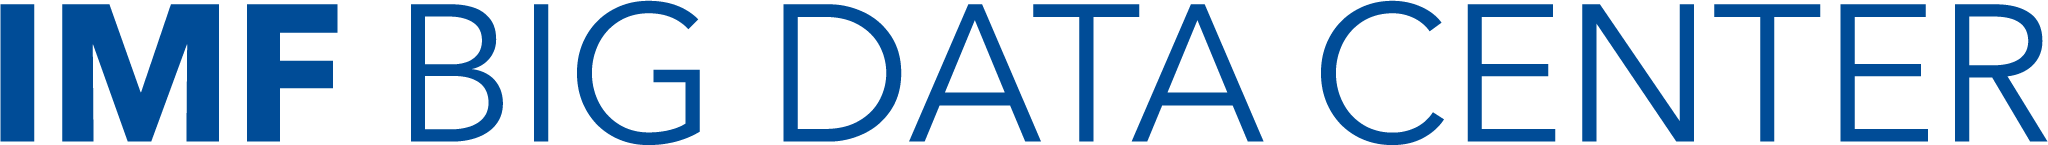

# Building statistics from satellite imageries


---

<br>**Contributors:** [Alessandra Sozzi](asozzi@imf.org) & [Mario Saraiva](msaraiva@imf.org)
<br> **Last update:** Oct-2026
<br> **Description:** This notebook showcase methods to derive builtup area and building footprints statistics and from satellite imageries.
<br> **References:**

Useful links and references

- [Google Earth Engine](https://earthengine.google.com/)
- [Create a google / gmail account if you do not have one already](https://support.google.com/mail/answer/56256?hl=en)
- [Try to log-on to google colab account with you gmail account](https://colab.research.google.com/)
- [Sign up for an Earth Engine account](https://earthengine.google.com/signup/)
- [Geemap website](https://geemap.org/)
- [Geemap book](https://book.geemap.org/)
- [Geemap YouTube videos](https://youtube.com/@giswqs)
- [Learn more about Google Earth Engine, usage and applications](https://courses.spatialthoughts.com/end-to-end-gee.html)
- [Dynamic World](https://dynamicworld.app/)
- [Explore Dynamic World data exploration tool here](https://dynamicworld.app/explore)
- [Microsoft Global ML Building Footprints](https://github.com/microsoft/GlobalMLBuildingFootprints)
- [H3: Uber’s Hexagonal Hierarchical Spatial Index](https://h3geo.org/)
- [Overture Maps Foundation](https://overturemaps.org/)

## Setup

#### Mount the drive and adjust the path

In [2]:
# Mounth the drive to access file in the Google Drive folder
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
# Set the main path for the workshop files
import os

# The workshop repository, downloaded from GitHub as a zip and unzipped into the top level of your Google Drive
ROOT = "/content/drive/MyDrive/imf_big_data_workshop_sti26-main"
data_path = os.path.join(ROOT, "data", "builtup")

# Check if working
print("Root path found: ", os.path.exists(ROOT))
print("Data path found: ", os.path.exists(data_path))


Root path found:  True
Data path found:  True


### Authenticate Google Earth Engine

In [4]:
from google.colab import userdata
import ee

ee.Authenticate()
# Pull the Earth Engine project ID from Colab Secrets (set via the 🔑 panel in the sidebar)
my_project_id = userdata.get('gee_project_id')
ee.Initialize(project=my_project_id)

### Libraries

In [5]:
import geemap

import pandas as pd
import geopandas as gpd

import matplotlib.pyplot as plt

# **Built-up area Statistics**

In this section, we will derive crop-land statistics using **Google Dynamic World** global land-cover dataset.

## Google Dynamic World

Dynamic World LULC is a near realtime 10m resolution global land use land cover dataset, produced using deep learning and sentinel-2 High-frequency imagery. It is freely available and openly licensed.
- [Dynamic World Website](https://www.dynamicworld.app/)
- [Dynamic World datasets on Earth Engine](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_DYNAMICWORLD_V1)

> Pasquarella, V. et al. "Dynamic World: Near real-time global 10 m land use land cover mapping." Nature Scientific Data (2022). https://www.nature.com/articles/s41597-022-01307-4

### 🏙️ **What defines built up areas in land cover maps?**

**Definition:**  
Areas dominated by **human-made structures and surfaces**, such as buildings, paved roads, parking lots, runways, and other impervious materials. These are typically **urban or industrial zones** where artificial surfaces replace natural land cover.

**Includes:**  
- Residential, commercial, and industrial built-up areas  
- Transportation infrastructure (roads, railways, airports)  
- Urban open areas dominated by concrete or asphalt  

**Excludes:**  
- Bare soil or exposed ground (classified as **Bare**)  
- Sparse rural settlements where vegetation is dominant  
- Construction sites with visible soil (may appear as **Bare** or **Crops**)  

**Spectral characteristics:**  
Built surfaces generally show **high reflectance in visible wavelengths** (especially red) and **low reflectance in near-infrared (NIR)** bands, resulting in low vegetation indices (e.g., NDVI).

### Country for this Excercise

In [6]:
country_name = "Timor-Leste"

### Extract Built-up Areas

In [7]:
# Load GAUL 2024 L1 and filter by country name
country_l1 = (ee.FeatureCollection("projects/sat-io/open-datasets/FAO/GAUL/GAUL_2024_L1")
              .filter(ee.Filter.eq('gaul0_name', country_name)))

# Define the time range
start_date = ee.Date('2025-01-01')
end_date = ee.Date('2025-12-31')

# Load the Dynamic World dataset
dw = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
    .filterDate(start_date, end_date) \
    .filterBounds(country_l1)

# Create a mode composite.
classification = dw.select('label');
dwComposite = classification.reduce(ee.Reducer.mode());

# Extract the Built Area class.
# See more https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_DYNAMICWORLD_V1#bands
# The resulting builtArea image is a binary image—with pixel value 1
# where the condition matched and 0 where it didn't.
built_class = 6
builtArea = dwComposite.eq(built_class)

We can add both the composite and the built area images to the Map to verify it.


In [8]:
# Set the map
Map = geemap.Map(basemap='HYBRID')
Map.centerObject(country_l1, 7);

# DW class colors
dwVisParams = {
  'min': 0,
  'max': 8,
  'palette': [
    '#419BDF', '#397D49', '#88B053', '#7A87C6', '#E49635', '#DFC35A',
    '#C4281B', '#A59B8F', '#B39FE1'
  ]
};

dwBuiltMaskParams = {
      'min': 0,
      'max': 1,
      'palette': ["white", "red"]
}

# Add the composite and the built mask to the map
Map.addLayer(dwComposite.clip(country_l1), dwVisParams, 'Classified Composite');
Map.addLayer(builtArea.clip(country_l1),  dwBuiltMaskParams, 'Built Areas');
Map

Map(center=[-8.820889853847406, 125.85278385455395], controls=(WidgetControl(options=['position', 'transparent…

###  Calculate zonal statistics

In [9]:
builtArea = (dwComposite
             .eq(built_class) # equal to built class
             .clipToCollection(country_l1)
             .selfMask()) # keep only pixels that match condition
nonBuiltArea = (dwComposite
                .neq(built_class)  # NOT equal to built class
                .clipToCollection(country_l1)
                .selfMask()) # keep only pixels that match condition

In [10]:
images = ee.List([nonBuiltArea, builtArea])
collection = ee.ImageCollection.fromImages(images)
collection = collection.toBands().rename(['non_built_area', 'built_area'])

In [ ]:
# Zonal statistics by region
geemap.zonal_stats(
    collection,                  # Raster layer
    country_l1,                   # Vector features (L1 regions)
    os.path.join(data_path, 'dynamic_world_bulit_share.csv'),           # Output filepath
    statistics_type='SUM',        # Sum of pixels
    scale=1000,                   # Spatial resolution
    verbose=True,
)

In [12]:
# let's map it to a dataframe using the geemap tool
df = geemap.csv_to_df(os.path.join(data_path, 'dynamic_world_bulit_share.csv'))

# Calculate built area percentage
df['percentage_built_area'] = df['built_area']*100 / (df['built_area'] + df['non_built_area'])

df.head(10)


,non_built_area,built_area,gaul0_name,continent,iso3_code,disp_en,map_code,gaul1_code,gaul0_code,gaul1_name,system:index,percentage_built_area
0,742.639216,7.000000,Timor-Leste,Asia,TLS,"Aileu, Timor-Leste",TLS,3084,276,Aileu,0000000000000000002c,0.933783
1,810.050980,8.000000,Timor-Leste,Asia,TLS,"Ainaro, Timor-Leste",TLS,3085,276,Ainaro,0000000000000000002d,0.977934
2,1489.513725,38.721569,Timor-Leste,Asia,TLS,"Baucau, Timor-Leste",TLS,3086,276,Baucau,0000000000000000002e,2.533744
3,1361.407843,35.729412,Timor-Leste,Asia,TLS,"Bobonaro, Timor-Leste",TLS,3087,276,Bobonaro,0000000000000000002f,2.557330
4,1203.941176,21.000000,Timor-Leste,Asia,TLS,"Covalima, Timor-Leste",TLS,3088,276,Covalima,00000000000000000030,1.714368
5,310.007843,62.756863,Timor-Leste,Asia,TLS,"Dili, Timor-Leste",TLS,3089,276,Dili,00000000000000000031,16.835516
6,764.152941,17.513725,Timor-Leste,Asia,TLS,"Ermera, Timor-Leste",TLS,3090,276,Ermera,00000000000000000032,2.240562
7,1825.600000,11.454902,Timor-Leste,Asia,TLS,"Lautém, Timor-Leste",TLS,3091,276,Lautém,00000000000000000033,0.623547
8,526.713725,31.756863,Timor-Leste,Asia,TLS,"Liquiçá, Timor-Leste",TLS,3092,276,Liquiçá,00000000000000000034,5.686398
9,1799.070588,11.478431,Timor-Leste,Asia,TLS,"Manatuto, Timor-Leste",TLS,3093,276,Manatuto,00000000000000000035,0.633975


In [13]:
import pandas as pd

# Summarize built vs non-built area by region
analysis_df = df[['gaul1_name', 'built_area', 'non_built_area', 'percentage_built_area']].copy()
analysis_df['total_area'] = analysis_df['built_area'] + analysis_df['non_built_area']
analysis_df = analysis_df.sort_values(by='percentage_built_area', ascending=False).reset_index(drop=True)

print("Summary Analysis of Built vs Non-Built Areas by Region in Timor-Leste:")
display(analysis_df)

# General descriptive metrics
total_built = analysis_df['built_area'].sum()
total_non_built = analysis_df['non_built_area'].sum()
national_built_share = (total_built / (total_built + total_non_built)) * 100

print(f"\nNational Summary Statistics:")
print(f"Total Built Area Pixels: {total_built:,.2f}")
print(f"Total Non-Built Area Pixels: {total_non_built:,.2f}")
print(f"Overall National Built-up Share: {national_built_share:.2f}%")

Summary Analysis of Built vs Non-Built Areas by Region in Timor-Leste:


,gaul1_name,built_area,non_built_area,percentage_built_area,total_area
0,Dili,62.756863,310.007843,16.835516,372.764706
1,Liquiçá,31.756863,526.713725,5.686398,558.470588
2,Oecussi,34.388235,796.270588,4.139875,830.658824
3,Bobonaro,35.729412,1361.407843,2.557330,1397.137255
4,Baucau,38.721569,1489.513725,2.533744,1528.235294
5,Ermera,17.513725,764.152941,2.240562,781.666667
6,Covalima,21.000000,1203.941176,1.714368,1224.941176
7,Manufahi,16.000000,1329.870588,1.188822,1345.870588
8,Ainaro,8.000000,810.050980,0.977934,818.050980
9,Aileu,7.000000,742.639216,0.933783,749.639216



National Summary Statistics:
Total Built Area Pixels: 312.80
Total Non-Built Area Pixels: 14,848.97
Overall National Built-up Share: 2.06%


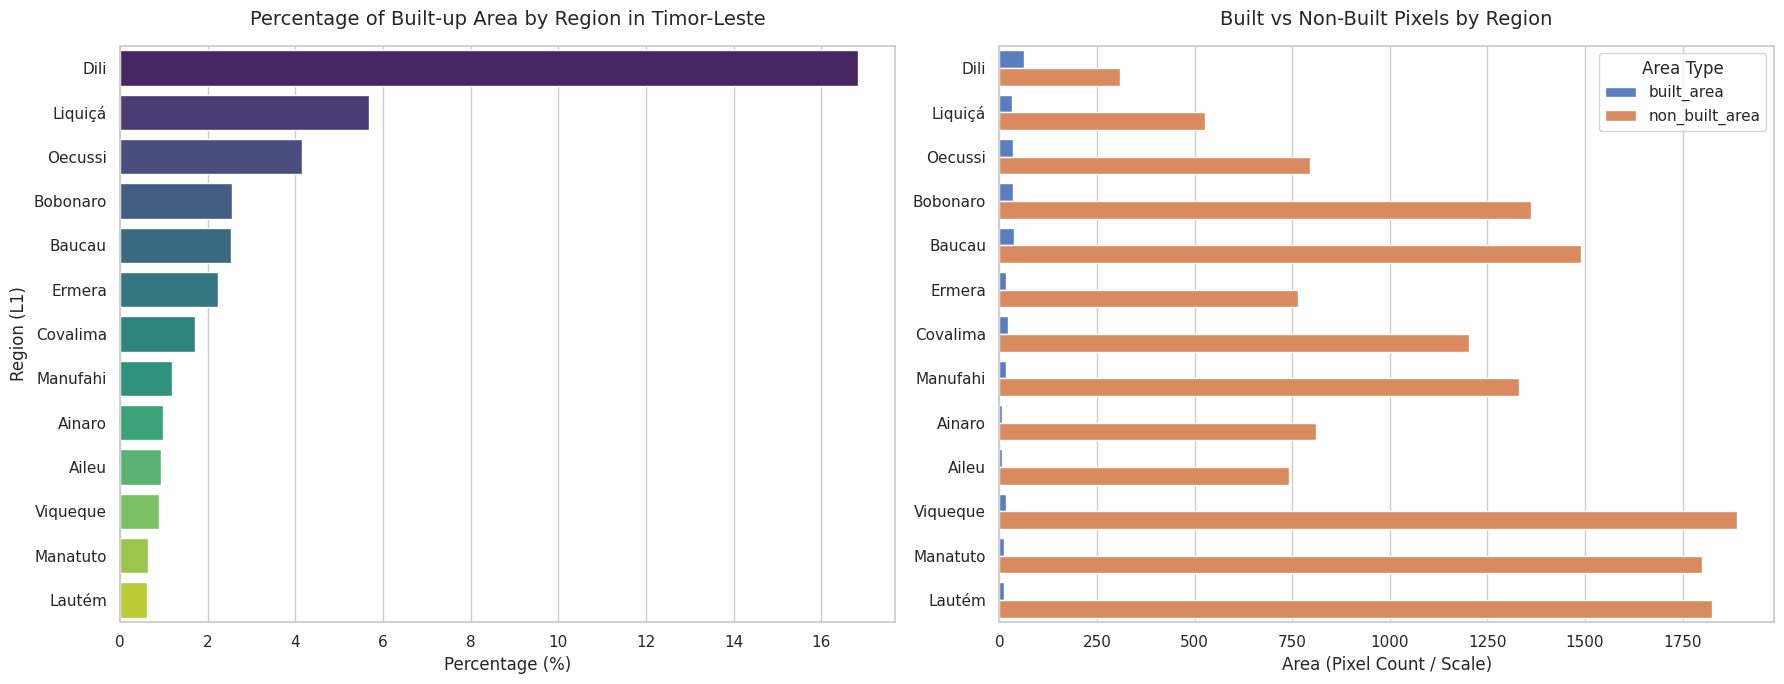

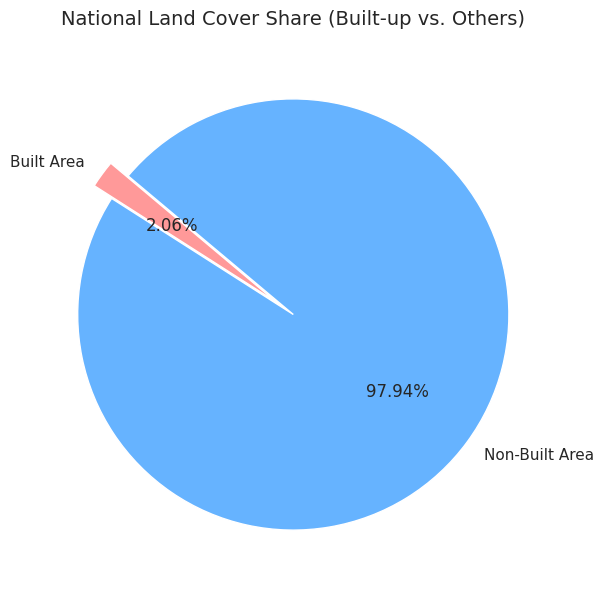

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the styling
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Chart 1: Bar chart of Percentage of Built Area by Region
sns.barplot(
    x='percentage_built_area',
    y='gaul1_name',
    data=analysis_df,
    ax=axes[0],
    palette='viridis',
    hue='gaul1_name',
    legend=False
)
axes[0].set_title('Percentage of Built-up Area by Region in Timor-Leste', fontsize=14, pad=15)
axes[0].set_xlabel('Percentage (%)', fontsize=12)
axes[0].set_ylabel('Region (L1)', fontsize=12)

# Chart 2: Stacked Bar Chart of Absolute Areas
# Normalize or plot absolute pixel distributions
analysis_df_melted = pd.melt(
    analysis_df,
    id_vars=['gaul1_name'],
    value_vars=['built_area', 'non_built_area'],
    var_name='Area Type',
    value_name='Pixels'
)

sns.barplot(
    x='Pixels',
    y='gaul1_name',
    hue='Area Type',
    data=analysis_df_melted,
    ax=axes[1],
    palette='muted'
)
axes[1].set_title('Built vs Non-Built Pixels by Region', fontsize=14, pad=15)
axes[1].set_xlabel('Area (Pixel Count / Scale)', fontsize=12)
axes[1].set_ylabel('', fontsize=12)

plt.tight_layout()
plt.show()

# Chart 3: National Share Pie Chart
plt.figure(figsize=(7, 7))
plt.pie(
    [total_built, total_non_built],
    labels=['Built Area', 'Non-Built Area'],
    autopct='%1.2f%%',
    startangle=140,
    colors=['#ff9999', '#66b3ff'],
    explode=(0.1, 0)
)
plt.title('National Land Cover Share (Built-up vs. Others)', fontsize=14, pad=15)
plt.show()

In [15]:
# Bar chart of built area per region
geemap.bar_chart(
    df,
    x='gaul1_name', y='percentage_built_area',
    max_rows=50,
    x_label='',
    y_label='Builtup Area %'
)

###  Years side-by-side

In [16]:
# Built-up (Dynamic World class 6) for a given year: most frequent label per pixel
def dw_built(year, region):
    return (ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
            .filterDate(f"{year}-01-01", f"{year+1}-01-01")
            .filterBounds(region)
            .select("label")
            .reduce(ee.Reducer.mode())
            .eq(6)
            .clip(region)
            .selfMask())

built_2019 = dw_built(2019, country_l1)
built_2025 = dw_built(2025, country_l1)

left_layer  = geemap.ee_tile_layer(built_2019, {"palette": ["red"]}, "Built-up 2019")
right_layer = geemap.ee_tile_layer(built_2025, {"palette": ["red"]}, "Built-up 2025")

Map = geemap.Map(center=[-8.56, 125.57], zoom=13, basemap="SATELLITE")   # Dili
Map.split_map(left_layer=left_layer, right_layer=right_layer)
Map

Map(center=[-8.56, 125.57], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_…

In [17]:
def s2_rgb(year, region):
    cs = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")
    return (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
            .filterDate(f"{year}-06-01", f"{year}-11-01")      # dry season
            .filterBounds(region)
            .linkCollection(cs, ["cs_cdf"])
            .map(lambda img: img.updateMask(img.select("cs_cdf").gte(0.6)))
            .median()
            .clip(region))

rgb_vis = {"bands": ["B4", "B3", "B2"], "min": 0, "max": 3000}

Map = geemap.Map(center=[-8.56, 125.57], zoom=13, basemap="SATELLITE")   # Dili
Map.split_map(
    left_layer=geemap.ee_tile_layer(s2_rgb(2019, country_l1), rgb_vis, "Sentinel-2 2019"),
    right_layer=geemap.ee_tile_layer(s2_rgb(2025, country_l1), rgb_vis, "Sentinel-2 2025"),
)
Map

Map(center=[-8.56, 125.57], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_…

# **Building Footprints**


## 🏗️ **What defines Building Footprints?**

**Building footprints** are polygon representations of the exact ground area covered by built structures such as houses, commercial buildings, and other man-made constructions. They provide a detailed, vector-based view of human settlements and are a key layer for understanding **urbanization, population distribution, and land-use change**.  

Building footprint datasets are typically derived from **high-resolution satellite imagery, aerial photos, or LiDAR data** using machine-learning and computer-vision methods. Global initiatives such as **Microsoft’s Global ML Building Footprints**, **Google Open Buildings**, and **Overture Maps** have made large-scale, open datasets available for urban analytics, disaster risk assessment, and infrastructure planning.

## Overture Maps

**Overture Maps** is an open, collaborative mapping project founded by the **Overture Maps Foundation**, a nonprofit initiative led by **Linux Foundation** members including **Microsoft, Meta, Amazon Web Services, and TomTom**. Its goal is to create high-quality, interoperable **open map data** that can serve as a reliable base layer for applications in navigation, urban planning, and geospatial analysis.  

Overture Maps aggregates and harmonizes data from multiple public and private sources — including **OpenStreetMap**, **government open data**, and partner contributions — into standardized global datasets such as **buildings**, **transportation networks**, **places of interest**, and **administrative boundaries**. Data is distributed in **GeoParquet** format for efficient cloud-native use, making it well-suited for large-scale analytics and integration with tools like **BigQuery**, **DuckDB**, or **GeoPandas**.  

> **Source:** [Overture Maps Foundation](https://overturemaps.org/)



### Install Extra Libraries

In [18]:
%%capture
!pip install h3

In [19]:
%%capture
!pip install overturemaps

In [20]:
import h3
import overturemaps
from shapely import wkb
from shapely import geometry
import requests
import geopandas as gpd

### Define our area of interest (AOI)


In [21]:
iso3 = "USA"
adm_level = "ADM1"

# Query the geoBoundaries API for the country/admin level
meta = requests.get(f"https://www.geoboundaries.org/api/current/gbOpen/{iso3}/{adm_level}/").json()

# Read the GeoJSON (use "simplifiedGeometryGeoJSON" for a lighter file)
country = gpd.read_file(meta["gjDownloadURL"])
print(country[["shapeName", "shapeISO"]].head())

# Select specific region
aoi_shape = geometry.shape(country[country.shapeName == "District of Columbia"].iloc[0].geometry)
aoi_shape

# Define bounding box
bbox = aoi_shape.bounds
bbox

        shapeName shapeISO
0     Mississippi    US-MS
1  North Carolina    US-NC
2        Oklahoma    US-OK
3        Virginia    US-VA
4   West Virginia    US-WV


(-77.11976132299998, 38.79165276400005, -76.90939725499999, 38.99511780500006)

In [22]:
country[country.shapeName == "District of Columbia"].explore(tiles="Esri.WorldGrayCanvas")

### Download building footprints

In [23]:
# Use the record_batch_reader method to pull the data into a PyArrow table.
# Specify we want to grab buildings data.
table = overturemaps.record_batch_reader("building", bbox).read_all()
table = table.combine_chunks()

In [24]:
# convert to dataframe
overture_df = table.to_pandas()

# DataFrame to GeoDataFrame, set crs
overture_gdf = gpd.GeoDataFrame(
    overture_df,
    geometry=overture_df['geometry'].apply(wkb.loads),
    crs="EPSG:4326"
)

print(overture_gdf.shape)

overture_gdf.head()

(347079, 24)


,id,names,sources,level,height,min_height,is_underground,num_floors,num_floors_underground,min_floor,...,roof_material,roof_shape,roof_direction,roof_orientation,roof_color,roof_height,geometry,has_parts,version,bbox
0,84bf97f9-6e14-479c-9afc-1a9642a9ffb6,None,"[{'property': '', 'dataset': 'Esri Community M...",NaN,NaN,NaN,False,NaN,NaN,NaN,...,None,None,NaN,None,None,NaN,"POLYGON ((-77.1197 38.85696, -77.11983 38.8569...",False,1,"{'xmin': -77.11983489990234, 'xmax': -77.11965..."
1,f4d7dc7e-b946-45ae-9b81-2def1f3e19e1,None,"[{'property': '', 'dataset': 'Esri Community M...",NaN,NaN,NaN,False,NaN,NaN,NaN,...,None,None,NaN,None,None,NaN,"POLYGON ((-77.11983 38.8569, -77.1197 38.85696...",False,1,"{'xmin': -77.11986541748047, 'xmax': -77.11969..."
2,b72924b6-d1b4-45c3-b59e-ea917d12f39a,None,"[{'property': '', 'dataset': 'Esri Community M...",NaN,NaN,NaN,False,NaN,NaN,NaN,...,None,None,NaN,None,None,NaN,"POLYGON ((-77.11986 38.85695, -77.11973 38.857...",False,1,"{'xmin': -77.11990356445312, 'xmax': -77.11972..."
3,550774fc-daea-4004-bafa-213093200c05,None,"[{'property': '', 'dataset': 'Esri Community M...",NaN,NaN,NaN,False,NaN,NaN,NaN,...,None,None,NaN,None,None,NaN,"POLYGON ((-77.11978 38.85664, -77.11973 38.856...",False,1,"{'xmin': -77.11981964111328, 'xmax': -77.11972..."
4,f4757934-e913-48fc-bcf9-a5220ebb740f,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",NaN,NaN,NaN,False,3.0,NaN,NaN,...,None,hipped,NaN,None,None,NaN,"POLYGON ((-77.11953 38.85604, -77.11956 38.856...",False,1,"{'xmin': -77.11967468261719, 'xmax': -77.11952..."


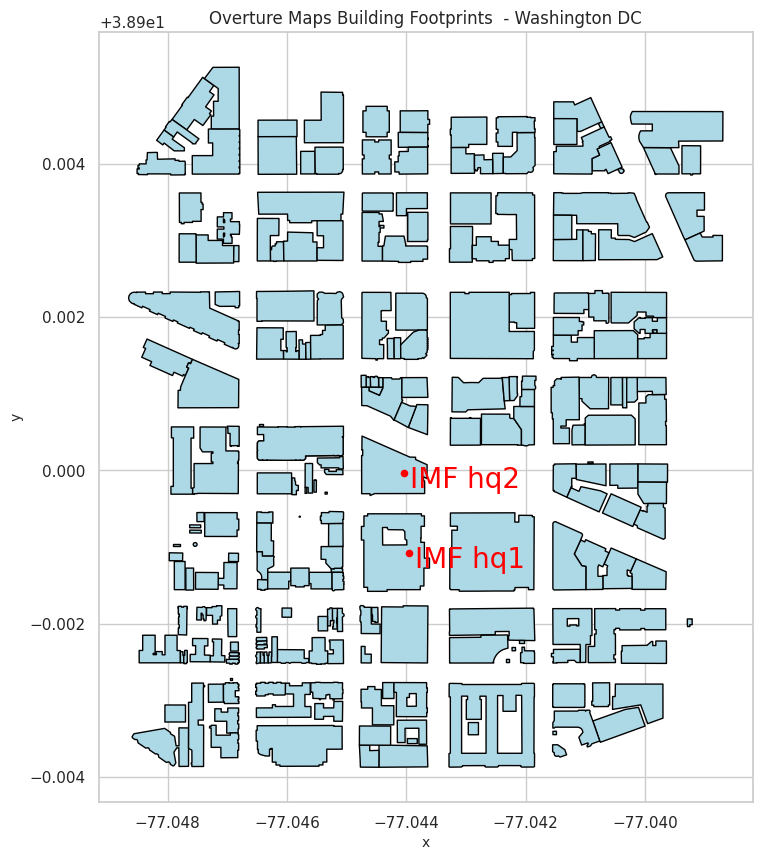

In [25]:
# Let's define a smaller area around DC downtown
xmin = -77.0478196131
xmax = -77.039270876
ymin = 38.8964034662
ymax = 38.9045279698

hqs = pd.DataFrame(
    {'x': [-77.043955, -77.044042],
     'y': [38.898922, 38.899961],
     'labels': ['IMF hq1', 'IMF hq2']})

fig, ax = plt.subplots(figsize=(10, 10))

# Plot the building footprints filtered within the bounding box
overture_gdf.cx[xmin:xmax, ymin:ymax].plot(ax=ax,
                  edgecolor="black",
                  facecolor="lightblue")

hqs.plot.scatter(x='x', y='y', ax=ax, color='red')
for i, row in hqs.iterrows():
    ax.text(row['x']+ 0.0001,     # horizontal padding
            row['y']+ 0.0001,     # vertical padding
            row['labels'], fontsize=20, ha='left', va='top', color='red')


# # Show the plot
plt.title("Overture Maps Building Footprints  - Washington DC")
plt.show()

In [26]:
overture_gdf.cx[xmin:xmax, ymin:ymax].explore(tiles="Esri.WorldGrayCanvas")

### Building Properties

| Property | Type | Description |
|---|---|---|
| `id` | string | Stable Overture feature identifier (128-bit string). |
| `version` | integer | Incremented when the feature changes. |
| `names` | object | Optional multilingual names; includes `primary`, `common` (by lang), and `rules` (variants). |
| `level` | integer | Vertical level for stacking/ordering (usually `1` for footprints). |
| `subtype` | enum(string) | Broad building purpose (e.g., `residential`, `commercial`, `industrial`, `education`, `medical`, `religious`, `transportation`, etc.). |
| `class` | enum(string) | Finer category (e.g., `house`, `apartments`, `office`, `warehouse`, `school`, `hospital`, `parking`, `temple`, …). |
| `has_parts` | boolean | `true` if the building has related `building_part` features. |
| `height` | number | Overall building height (SI units; meters). |
| `num_floors` | integer | Count of above-ground floors. |
| `num_floors_underground` | integer | Count of below-ground floors. |
| `is_underground` | boolean | `true` if the structure is underground. |
| `roof_height` | number | Height of roof structure (if available). |
| `roof_shape` | enum(string) | Roof form (e.g., `flat`, `gabled`, `hipped`, …). |
| `roof_material` | enum(string) | Roof material (e.g., `metal`, `tile`, `concrete`, …). |
| `facade_material` | enum(string) | Exterior wall material (e.g., `brick`, `stone`, `wood`, …). |
| `sources` | array(object) | Provenance per property; each item has `dataset`, `property` (JSON-pointer to the field), and `confidence` (0–1). |
| `ext_*` | any | Customer/user extensions (namespaced as `ext_…`). |

> **Notes**
> - Many attributes (subtype/class/materials) are harmonized from **OSM tags** and other providers into fixed enumerations defined by the schema.  
> - Measurements follow **SI units** and are provided as scalars **without unit strings**.  
> - If a building has internal segmentation (e.g., wings/sections), those appear as separate features under **`building_part`** with similar shape/height properties.

**Docs:** See the official [schema pages](https://docs.overturemaps.org/schema/concepts/by-theme/buildings/) for full enums and examples

Number of records missing subtype: 155748, 45%



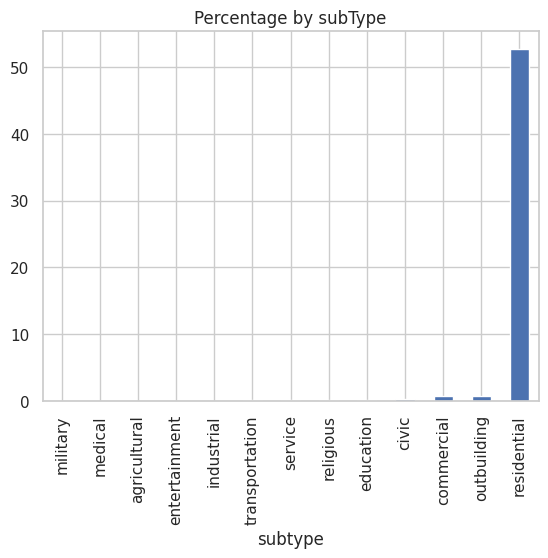

In [27]:
# Different types of buildings
print(f"Number of records missing subtype: {overture_gdf['subtype'].isna().sum()}, {round(overture_gdf['subtype'].isna().sum()*100/overture_gdf.shape[0])}%")
print()
(overture_gdf
  .groupby('subtype').size()
  .sort_values()*100/overture_gdf.shape[0]).plot(
    kind='bar', title="Percentage by subType");

In [28]:
building_properties = ['height', 'has_parts', 'is_underground', 'num_floors',
                      'num_floors_underground', 'min_height', 'min_floor', 'facade_color',
                      'facade_material', 'roof_material', 'roof_shape', 'roof_direction',
                      'roof_orientation', 'roof_color', 'roof_height']

(overture_gdf[overture_gdf.subtype=="residential"][building_properties].isna().sum()*100 /
 overture_gdf[overture_gdf.subtype=="residential"].shape[0]).to_frame(name="Percentage of NAs")

,Percentage of NAs
height,53.724740
has_parts,0.000000
is_underground,0.000000
num_floors,69.319369
num_floors_underground,99.987968
min_height,100.000000
min_floor,99.998906
facade_color,99.995625
facade_material,99.890618
roof_material,99.995078


### H3 binning

## 🧩 **H3 Spatial Indexing**

**H3** is a hierarchical, hexagon-based **spatial indexing system** developed by Uber for efficiently representing and analyzing geospatial data. It divides the Earth’s surface into a continuous grid of **hexagonal cells** (and a few pentagons) at multiple resolutions, from coarse (global) to fine (sub-meter). Each hexagon is assigned a unique **H3 index**, allowing complex spatial operations—such as aggregation, proximity analysis, and spatial joins—to be performed quickly and at scale.  

Unlike square grids, hexagons minimize edge effects and provide more uniform adjacency, making H3 particularly useful for **big geospatial data**, **mobility analytics**, **raster-to-vector transformations**, and **spatial downscaling or upscaling**. The indexing hierarchy (resolutions 0–15) supports seamless zooming and consistent spatial partitioning across datasets.

> **Reference:** [H3: Uber’s Hexagonal Hierarchical Spatial Index](https://h3geo.org/)

In [29]:
h3_level = 10 # ≈ 13.6 km²

# Convert lat/long centroids of each building footprint into the coresponding h3 cell ID
def lat_lng_to_h3(row):
    return h3.latlng_to_cell(
      row.geometry.centroid.y, row.geometry.centroid.x, h3_level)

overture_gdf[f'h3_level_{h3_level}'] = overture_gdf.apply(lat_lng_to_h3, axis=1)


In [30]:
overture_gdf = overture_gdf[overture_gdf.within(aoi_shape)]

In [31]:
overture_gdf.head()

,id,names,sources,level,height,min_height,is_underground,num_floors,num_floors_underground,min_floor,...,roof_shape,roof_direction,roof_orientation,roof_color,roof_height,geometry,has_parts,version,bbox,h3_level_10
35836,52e8f624-f39d-4271-bfa9-c41f23292c8f,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",NaN,5.543577,NaN,False,NaN,NaN,NaN,...,None,NaN,None,None,NaN,"POLYGON ((-77.11237 38.93354, -77.1123 38.9334...",False,2,"{'xmin': -77.11237335205078, 'xmax': -77.11215...",8a2aa84c5947fff
35837,86e57a7f-ddd0-41aa-81ad-256f84da7641,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",NaN,5.852316,NaN,False,NaN,NaN,NaN,...,None,NaN,None,None,NaN,"POLYGON ((-77.11227 38.93366, -77.1123 38.9336...",False,2,"{'xmin': -77.11246490478516, 'xmax': -77.11226...",8a2aa84c5947fff
35838,8a53afe2-5420-4eef-ae11-4cf4ad4363b6,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",NaN,6.149880,NaN,False,NaN,NaN,NaN,...,None,NaN,None,None,NaN,"POLYGON ((-77.11491 38.93509, -77.11496 38.935...",False,2,"{'xmin': -77.1150894165039, 'xmax': -77.114883...",8a2aa84c591ffff
35839,84b937db-0bf9-4931-bd93-1676aad8749a,None,"[{'property': '', 'dataset': 'Esri Community M...",NaN,NaN,NaN,False,NaN,NaN,NaN,...,None,NaN,None,None,NaN,"POLYGON ((-77.11519 38.93497, -77.11517 38.935...",False,1,"{'xmin': -77.115234375, 'xmax': -77.1151657104...",8a2aa84c591ffff
35840,347de185-2593-45f3-9c8d-98e30920f35e,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",NaN,6.800000,NaN,False,NaN,NaN,NaN,...,None,NaN,None,None,NaN,"POLYGON ((-77.11398 38.9355, -77.11394 38.9353...",False,1,"{'xmin': -77.11398315429688, 'xmax': -77.11382...",8a2aa84c5907fff


In [32]:
# Count number of buildings by H3 cell
om_n_buildings_by_h3 = (
    overture_gdf.groupby([f'h3_level_{h3_level}'])
    .agg(
        {'height': 'mean',
         'id': 'count',
         'subtype': pd.Series.mode}
    )
    .reset_index()
    .rename(columns={'id': 'n_buildings'})
)

print(om_n_buildings_by_h3.shape)

om_n_buildings_by_h3.head()

(9000, 4)


,h3_level_10,height,n_buildings,subtype
0,8a2aa8408247fff,7.300000,7,residential
1,8a2aa840824ffff,5.522629,18,residential
2,8a2aa8408257fff,6.728571,8,residential
3,8a2aa840825ffff,6.631020,16,residential
4,8a2aa84082cffff,4.844448,6,residential


In [33]:
# Add geometry of the hexbins
om_n_buildings_by_h3['geometry'] = om_n_buildings_by_h3.h3_level_10.apply(lambda x: h3.cells_to_geo([x]))
om_n_buildings_by_h3['geometry'] = om_n_buildings_by_h3['geometry'].apply(geometry.shape)

# Convert into geopandas dataframe
om_n_buildings_by_h3_geo = gpd.GeoDataFrame(
    om_n_buildings_by_h3,
    geometry='geometry',
    crs=4326
)

om_n_buildings_by_h3_geo.head()

,h3_level_10,height,n_buildings,subtype,geometry
0,8a2aa8408247fff,7.300000,7,residential,"POLYGON ((-77.04001 38.99377, -77.03914 38.993..."
1,8a2aa840824ffff,5.522629,18,residential,"POLYGON ((-77.0396 38.99268, -77.03874 38.9928..."
2,8a2aa8408257fff,6.728571,8,residential,"POLYGON ((-77.04152 38.99406, -77.04065 38.994..."
3,8a2aa840825ffff,6.631020,16,residential,"POLYGON ((-77.04111 38.99297, -77.04024 38.993..."
4,8a2aa84082cffff,4.844448,6,residential,"POLYGON ((-77.04372 38.99246, -77.04285 38.992..."


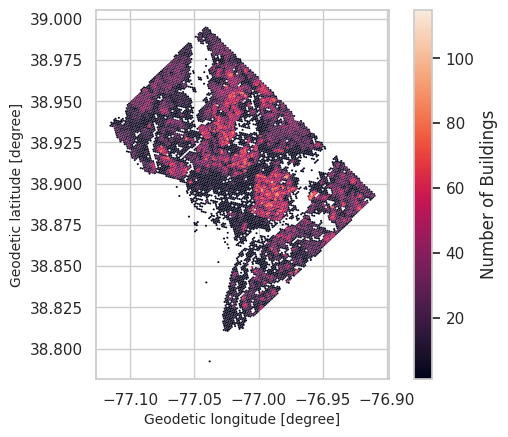

In [34]:
# Plot number of buildings by h3 on a map with hexagon contours removed
om_n_buildings_by_h3_geo.plot(column="n_buildings",
                           edgecolor="none",
                           legend=True,
                           legend_kwds={"label": "Number of Buildings"});

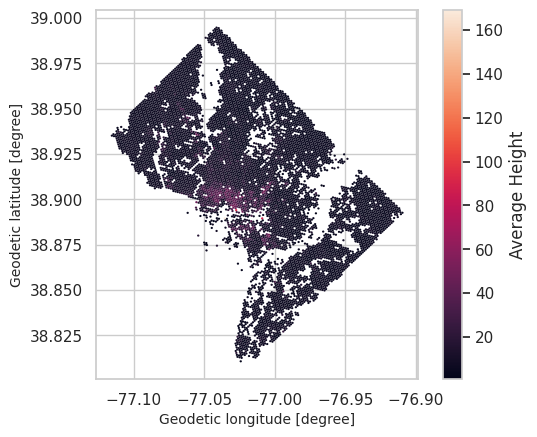

In [37]:
# Plot avg height by h3 on a map
om_n_buildings_by_h3_geo[~om_n_buildings_by_h3_geo.height.isna()].plot(column="height",
                           legend=True,
                           edgecolor="none",
                           legend_kwds={"label": "Average Height"});

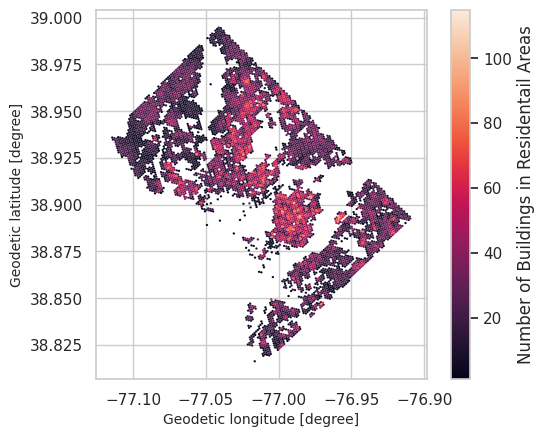

In [38]:
# Plot number of buildings by h3 on a map
om_n_buildings_by_h3_geo[om_n_buildings_by_h3_geo.subtype.astype(str)=="residential"].plot(column="n_buildings",
                           legend=True,
                           edgecolor="none",
                           legend_kwds={"label": "Number of Buildings in Residentail Areas"});